# Final Project - ARTI-405 - Group 1 - Model Development
Dylan, Eddie, Brandon, and Caden

**Team work plan (from the group chat):**
- **Caden:** Data Cleaning and Preprocessing, exploratory checks and feature preparation (completed below).
- **Eddie:** Model Development.
- **Dylan:** Streamlit Deployment and GitHub Repository.
- **Brandon:** Project Report Document.
- **Everyone:** Project Presentation; Caden and Eddie also proofread the report.

**Dataset:** [Andrei Novikov, Used Cars Dataset](https://www.kaggle.com/datasets/andreinovikov/used-cars-dataset?select=cars.csv). Target `price` = advertised **listing** price (USD), not confirmed sale price.

**To run:** Download the Kaggle `cars.csv` and put it beside this notebook (or in `data/cars.csv`). Do **not** commit the 138 MB dataset to GitHub.

**Important:** Learned preprocessing (medians, min-max ranges, category frequencies) is defined here but fitted to **training data only** after Eddie splits X/y. Dylan's original *Model Development*, *Model Comparison*, and *Final Selection* headings and reminders remain unchanged below.

## Import Data and Packages

In [1]:
# All package imports are in one place so we can reuse them later.
from pathlib import Path
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder

In [2]:
# Match Dylan's notebook and keep this usable in Jupyter or VS Code.
DATA_CANDIDATES = [
    Path("data/cars.csv"),
    Path("cars.csv"),
    Path("data/raw/cars.csv"),
    Path("../data/cars.csv"),
]
DATA_PATH = next((p for p in DATA_CANDIDATES if p.is_file()), None)
if DATA_PATH is None:
    raise FileNotFoundError(
        "The Kaggle dataset is not included. Download 'cars.csv' from "
        "https://www.kaggle.com/datasets/andreinovikov/used-cars-dataset "
        "and save it as data/cars.csv (or next to the notebook)."
    )

cars_raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Loaded: {DATA_PATH} | rows={len(cars_raw):,} | columns={len(cars_raw.columns)}")
print("Original column names:", cars_raw.columns.tolist())
display(cars_raw.head(5))

Loaded: cars.csv | rows=762,091 | columns=20
Original column names: ['manufacturer', 'model', 'year', 'mileage', 'engine', 'transmission', 'drivetrain', 'fuel_type', 'mpg', 'exterior_color', 'interior_color', 'accidents_or_damage', 'one_owner', 'personal_use_only', 'seller_name', 'seller_rating', 'driver_rating', 'driver_reviews_num', 'price_drop', 'price']


,manufacturer,model,year,mileage,engine,transmission,drivetrain,fuel_type,mpg,exterior_color,interior_color,accidents_or_damage,one_owner,personal_use_only,seller_name,seller_rating,driver_rating,driver_reviews_num,price_drop,price
0,Acura,ILX Hybrid 1.5L,2013,92945.0,"1.5L I-4 i-VTEC variable valve control, engine...",Automatic,Front-wheel Drive,Gasoline,39-38,Black,Parchment,0.0,0.0,0.0,Iconic Coach,NaN,4.4,12.0,300.0,13988.0
1,Acura,ILX Hybrid 1.5L,2013,47645.0,1.5L I4 8V MPFI SOHC Hybrid,Automatic CVT,Front-wheel Drive,Hybrid,39-38,Gray,Ebony,1.0,1.0,1.0,Kars Today,NaN,4.4,12.0,NaN,17995.0
2,Acura,ILX Hybrid 1.5L,2013,53422.0,1.5L I4 8V MPFI SOHC Hybrid,Automatic CVT,Front-wheel Drive,Hybrid,39-38,Bellanova White Pearl,Ebony,0.0,1.0,1.0,Weiss Toyota of South County,4.3,4.4,12.0,500.0,17000.0
3,Acura,ILX Hybrid 1.5L,2013,117598.0,1.5L I4 8V MPFI SOHC Hybrid,Automatic CVT,Front-wheel Drive,Hybrid,39-38,Polished Metal Metallic,NaN,0.0,1.0,1.0,Apple Tree Acura,NaN,4.4,12.0,675.0,14958.0
4,Acura,ILX Hybrid 1.5L,2013,114865.0,1.5L I4 8V MPFI SOHC Hybrid,Automatic CVT,Front-wheel Drive,Hybrid,39-38,NaN,Ebony,1.0,0.0,1.0,Herb Connolly Chevrolet,3.7,4.4,12.0,300.0,14498.0


## Data Preprocessing

I am preparing the data for our Streamlit used-car price estimator. I kept the raw source in `cars_raw` so we can compare original and cleaned records. The notebook checks missing values, duplicates, category consistency, unrealistic prices, and feature selection before the models are trained.

In [3]:
# Standardize column names so later code doesn't depend on spaces or capital letters.
cars = cars_raw.copy()
cars.columns = (cars.columns.astype(str)
                .str.strip().str.lower()
                .str.replace(r"[^a-z0-9]+", "_", regex=True)
                .str.strip("_"))

# Allow a few common alternate spellings without confusing this dataset with another one.
rename_columns = {
    "make": "manufacturer",
    "milage": "mileage",
    "car_model": "model",
    "listing_price": "price",
}
cars.rename(columns={old: new for old, new in rename_columns.items()
                     if old in cars.columns and new not in cars.columns}, inplace=True)

required = {"manufacturer", "model", "year", "mileage", "transmission", "engine", "price"}
missing_required = sorted(required.difference(cars.columns))
if missing_required:
    raise ValueError(
        f"Expected the Novikov cars.csv. These required columns were missing: {missing_required}. "
        f"Found: {cars.columns.tolist()}"
    )

# Normalize category labels: e.g. " Toyota  " and "TOYOTA" become the same category.
text_columns = ["manufacturer", "model", "transmission", "engine", "fuel_type", "drivetrain",
                "exterior_color", "interior_color", "accidents_or_damage",
                "one_owner", "personal_use_only"]
for col in text_columns:
    if col in cars.columns:
        cars[col] = (cars[col].astype("string").str.strip()
                     .str.replace(r"\s+", " ", regex=True)
                     .str.lower())
        cars[col] = cars[col].replace({"": pd.NA, "nan": pd.NA,
                                      "none": pd.NA, "null": pd.NA, "n/a": pd.NA})

# Clean price, mileage, and year (numeric data may contain $ signs or commas).
def parse_number(series):
    return pd.to_numeric(
        series.astype("string").str.replace(r"[^0-9.\-]", "", regex=True),
        errors="coerce",
    ).astype("float64")

for col in ["price", "mileage", "year"]:
    cars[col] = parse_number(cars[col])

# The interface sketches show "engine size". Extract the displacement (e.g. 2.0 L),
# rather than encoding long, highly variable engine descriptions as categories.
# Electric cars or descriptions without liters become missing and will be imputed later.
engine_text = cars["engine"].astype("string")
engine_liters = engine_text.str.extract(
    r"(?i)(?<!\d)(\d{1,2}(?:\.\d+)?)\s*(?:l\b|liters?\b)", expand=False
)
cars["engine_size_liters"] = pd.to_numeric(engine_liters, errors="coerce")

# Implausible numeric INPUTS are treated as missing and imputed on training data.
# Do not impute the TARGET price: rows without a legitimate target cannot be trained.
reference_year = 2023  # Kaggle source lists used-car listings from April 2023
cars.loc[~cars["year"].between(1900, reference_year + 2), "year"] = np.nan
cars.loc[~cars["mileage"].between(0, 1_000_000), "mileage"] = np.nan
cars.loc[~cars["engine_size_liters"].between(0.5, 12), "engine_size_liters"] = np.nan

original_count = len(cars)
bad_target = cars["price"].isna() | (cars["price"] <= 0)
cars = cars.loc[~bad_target].copy()
print(f"Removed {bad_target.sum():,} records with missing/nonpositive price "
      f"({original_count:,} -> {len(cars):,}).")

Removed 0 records with missing/nonpositive price (762,091 -> 762,091).


### Missing Values

Top missing-value columns after initial cleaning:


,missing_count,missing_pct
price_drop,351979,46.19
seller_rating,213973,28.08
mpg,142071,18.64
interior_color,56975,7.48
engine_size_liters,44711,5.87
driver_rating,31632,4.15
one_owner,31483,4.13
personal_use_only,24852,3.26
accidents_or_damage,24212,3.18
fuel_type,22927,3.01


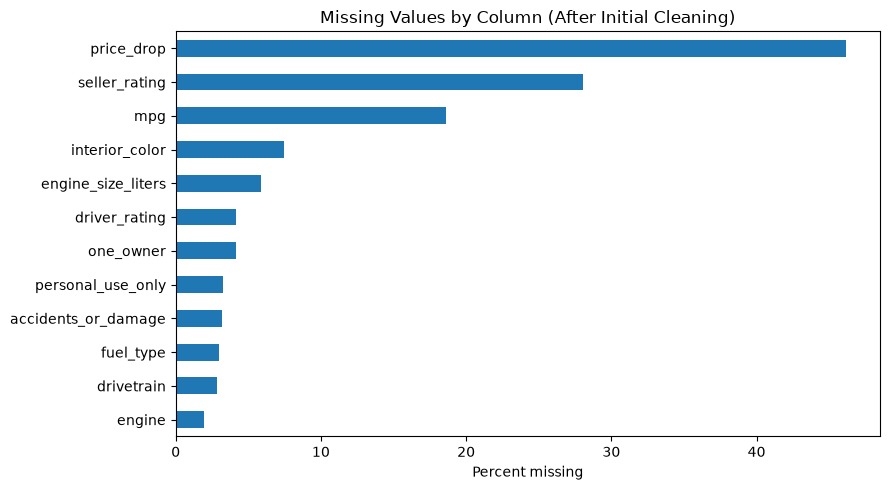

In [4]:
# Count missing values BEFORE any imputation; the learned fill values must come from training only.
missing_summary = pd.DataFrame({
    "missing_count": cars.isna().sum(),
    "missing_pct": (cars.isna().mean() * 100).round(2),
}).sort_values("missing_pct", ascending=False)
print("Top missing-value columns after initial cleaning:")
display(missing_summary.head(20))

# Optional plot for the final report; these are actual counts only once cars.csv is loaded.
fig, ax = plt.subplots(figsize=(9, 5))
missing_summary.loc[missing_summary.missing_count.gt(0), "missing_pct"].head(12).sort_values().plot.barh(ax=ax)
ax.set(title="Missing Values by Column (After Initial Cleaning)", xlabel="Percent missing", ylabel="")
plt.tight_layout()
plt.show()

### Duplicate Rows

In [5]:
# Only remove exact duplicates. Different seller listings with similar cars can still be valid.
exact_duplicates = int(cars.duplicated().sum())
cars = cars.drop_duplicates().reset_index(drop=True)
print(f"Exact duplicate rows removed: {exact_duplicates:,}")
print(f"Records remaining: {len(cars):,}")

Exact duplicate rows removed: 9,145
Records remaining: 752,946


### Inconsistent Categories

In [6]:
# Compare the original raw text fields to cleaned values before making the UI categories simpler.
print('Distinct labels before simplifying transmissions:')
for col in ['manufacturer', 'model', 'transmission']:
    print(f"{col}: {cars[col].nunique(dropna=True):,}")

# The Kaggle file has many descriptions such as '6-speed automatic' and
# '8-speed automatic'. A dropdown asking for 1,000+ transmission variants
# would be confusing, so convert them to broad categories. Keep the raw
# details in cars_raw for reference. Mapping is based only on the input text,
# not learned from price/labels, so it is safe before the train/test split.
def simplify_transmission(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    if not text or text in {'nan', 'none', 'unknown', 'n/a'}:
        return np.nan
    if re.search(r'dual.?clutch|\bdct\b|\bdsg\b|\bpdk\b|auto.?shift|double.?clutch', text):
        return 'dual-clutch'
    if re.search(r'\bcvt\b|continuously variable', text):
        return 'cvt'
    if re.search(r'\bmanual\b|\bm/t\b|stick shift', text):
        return 'manual'
    if re.search(r'\bautomatic\b|\ba/t\b|\bauto\b|tiptronic', text):
        return 'automatic'
    return 'other/unspecified'

# Preserve original transmission wording so distinct listings are not accidentally
# treated as exact duplicates merely because two labels share the same broad category.
cars['transmission_detail'] = cars['transmission'].copy()
cars['transmission'] = cars['transmission'].map(simplify_transmission)
print('\nDistinct labels AFTER simplifying transmissions:',
      cars['transmission'].nunique(dropna=True))
for col in ['manufacturer', 'model', 'transmission']:
    print(f'\n{col}: {cars[col].nunique(dropna=True):,} distinct values')
    display(cars[col].value_counts(dropna=False).head(10).rename('count').to_frame())

# The dataset has no reliable overall 'condition' score. We will not invent one.

Distinct labels before simplifying transmissions:
manufacturer: 30
model: 11,922
transmission: 1,144

Distinct labels AFTER simplifying transmissions: 5

manufacturer: 30 distinct values


,count
manufacturer,
ford,78851
toyota,59155
chevrolet,55485
nissan,47809
jeep,41192
mercedes-benz,40461
honda,37264
bmw,37077
kia,34511



model: 11,922 distinct values


,count
model,
fusion se,3172
sportage lx,2847
corolla le,2834
glc 300 base 4matic,2667
sentra sv,2636
explorer xlt,2542
rogue sv,2524
optima lx,2502
tundra sr5,2455



transmission: 5 distinct values


,count
transmission,
automatic,571630
cvt,113536
dual-clutch,27085
manual,23729
NaN,9496
other/unspecified,7470


### Outliers

Outside price band $500–$500,000: below=14, above=55
Removed 69 out-of-scope price records; 752,877 usable listings remain for the general-market model.
price: min=500.00, median=27,990.00, max=500,000.00; 3×IQR flags=10,558
mileage: min=0.00, median=45,615.00, max=999,999.00; 3×IQR flags=1,792
year: min=1,915.00, median=2,019.00, max=2,024.00; 3×IQR flags=6,584
engine_size_liters: min=0.65, median=2.50, max=8.40; 3×IQR flags=0


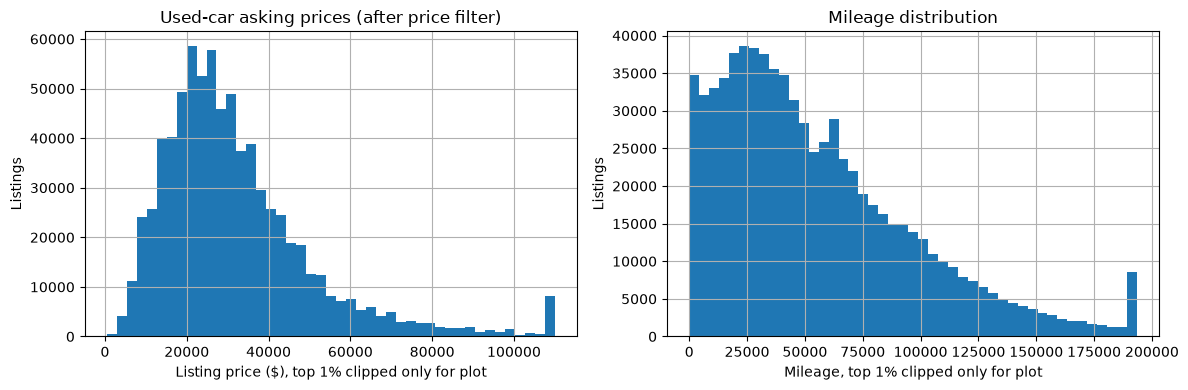

In [7]:
# A $1 listing and a $1,000,000,000 listing were visible in the real run.
# Both are poor training labels for a general used-car estimator.
# For this *general-market* app, use a documented, configurable price band.
# This is a project scope choice, NOT a claim that all vehicles outside the
# band are fraudulent: some luxury/collector cars may genuinely cost more.
MIN_REASONABLE_PRICE = 500
MAX_REASONABLE_PRICE = 500_000

n_before_price_filter = len(cars)
under_min = int((cars['price'] < MIN_REASONABLE_PRICE).sum())
over_max = int((cars['price'] > MAX_REASONABLE_PRICE).sum())
print(f'Outside price band ${MIN_REASONABLE_PRICE:,}–${MAX_REASONABLE_PRICE:,}: '
      f'below={under_min:,}, above={over_max:,}')

price_in_scope = cars['price'].between(MIN_REASONABLE_PRICE, MAX_REASONABLE_PRICE)
cars = cars.loc[price_in_scope].reset_index(drop=True)
print(f'Removed {n_before_price_filter - len(cars):,} out-of-scope price records; '
      f'{len(cars):,} usable listings remain for the general-market model.')
assert len(cars) > 0, 'No valid listings remained; review the configured price band.'

# Flag unusual values without removing every legitimately expensive car.
for col in ['price', 'mileage', 'year', 'engine_size_liters']:
    q1, q3 = cars[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 3 * iqr, q3 + 3 * iqr
    n_flags = int(((cars[col] < low) | (cars[col] > high)).sum())
    print(f'{col}: min={cars[col].min():,.2f}, median={cars[col].median():,.2f}, '
          f'max={cars[col].max():,.2f}; 3×IQR flags={n_flags:,}')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
cars['price'].clip(upper=cars['price'].quantile(.99)).hist(bins=45, ax=axes[0])
axes[0].set(xlabel='Listing price ($), top 1% clipped only for plot',
            ylabel='Listings', title='Used-car asking prices (after price filter)')
cars['mileage'].clip(upper=cars['mileage'].quantile(.99)).hist(bins=45, ax=axes[1])
axes[1].set(xlabel='Mileage, top 1% clipped only for plot', ylabel='Listings',
            title='Mileage distribution')
plt.tight_layout()
plt.show()

## Exploratory Data Analysis

Price summary after the documented price filter (USD):


,price
count,752877.000000
mean,32466.779712
std,22034.114966
min,500.000000
10%,13271.000000
25%,19595.000000
50%,27990.000000
75%,39485.000000
90%,54538.400000
99%,109990.000000


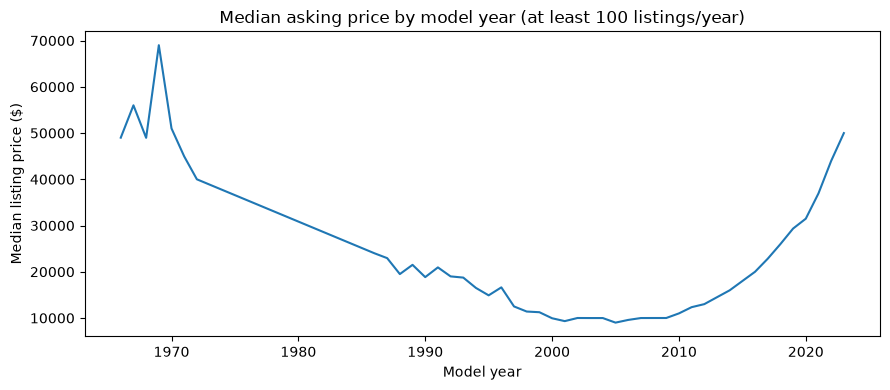

Spearman correlations among numeric variables:


,price,year,mileage,engine_size_liters
price,1.000,0.651,-0.650,0.349
year,0.651,1.000,-0.755,-0.091
mileage,-0.650,-0.755,1.000,0.113
engine_size_liters,0.349,-0.091,0.113,1.000


In [8]:
# Look for patterns we can show in the report after cleaning.
print('Price summary after the documented price filter (USD):')
display(cars['price'].describe(percentiles=[.10, .25, .50, .75, .90, .99]).to_frame('price'))

# Very old cars sometimes have only a handful of listings; connecting their
# medians can make the price/year line look wildly erratic. Plot only years
# represented by at least 100 listings and say so in the graph title.
year_stats = cars.groupby('year', dropna=True)['price'].agg(['median', 'count']).sort_index()
year_stats_shown = year_stats.loc[year_stats['count'] >= 100]
if len(year_stats_shown):
    fig, ax = plt.subplots(figsize=(9, 4))
    year_stats_shown['median'].plot(ax=ax)
    ax.set(title='Median asking price by model year (at least 100 listings/year)',
           xlabel='Model year', ylabel='Median listing price ($)')
    plt.tight_layout()
    plt.show()
else:
    print('Not enough records per year for the median-by-year plot.')

print('Spearman correlations among numeric variables:')
display(cars[['price', 'year', 'mileage', 'engine_size_liters']]
        .corr(method='spearman').round(3))

### Feature Selection

In [9]:
# Six input features match the proposed app: make, model, year, mileage,
# transmission type, and engine displacement. Only features that the user
# can supply at prediction time are included. No price_drop or seller data.
NUMERIC_FEATURES = ['year', 'mileage', 'engine_size_liters']
CATEGORICAL_FEATURES = ['manufacturer', 'model', 'transmission']
FEATURE_COLUMNS = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET_COLUMN = 'price'

X = cars[FEATURE_COLUMNS].copy()
for col in CATEGORICAL_FEATURES:
    # Avoid ambiguous pandas.NA in sklearn's categorical imputer.
    X[col] = X[col].astype(object).where(X[col].notna(), np.nan)
for col in NUMERIC_FEATURES:
    X[col] = pd.to_numeric(X[col], errors='coerce').astype('float64')
y = cars[TARGET_COLUMN].copy()

print(f'Features: {FEATURE_COLUMNS}')
print(f'X shape: {X.shape}; y shape: {y.shape}')
print('Missing values in selected features (imputed on TRAIN rows only):')
display(X.isna().sum().rename('missing_count').to_frame())

Features: ['year', 'mileage', 'engine_size_liters', 'manufacturer', 'model', 'transmission']
X shape: (752877, 6); y shape: (752877,)
Missing values in selected features (imputed on TRAIN rows only):


,missing_count
year,0
mileage,477
engine_size_liters,43890
manufacturer,0
model,0
transmission,9494


### Normalization

The numeric inputs are scaled into **0–1 using training-set statistics**, and categorical columns become one-hot 0/1 indicators. All price values remain in **actual dollars**. Long vehicle-model labels are grouped with `max_categories=120` per categorical feature to control memory use. The source dataset's many transmission descriptions are mapped to simple values for the Streamlit dropdown. The preprocessing transformer is intentionally **not fitted to the entire dataset**.

(Remember, our goal is to get all variables to be a value between 0 and 1)

#### Scaling

In [10]:
# Numeric pipeline: learn the median from training rows only, then scale to [0,1]
# based on the training range. Unseen test data can fall just outside 0-1;
# clip=True keeps it in [0,1] for deployment.
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", MinMaxScaler(clip=True)),
])
print(numeric_pipeline)

Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', MinMaxScaler(clip=True))])


#### One-Hot Encoding

In [11]:
# Group very rare model names so encoding will not produce thousands of
# columns. This frequency-based grouping is learned on TRAIN rows only.
# max_categories is a ceiling PER categorical field, not per entire model.
# New/unseen car models map to the infrequent category (when one exists).
categorical_pipeline = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
    ('encoder', OneHotEncoder(handle_unknown='infrequent_if_exist',
                              min_frequency=50, max_categories=120)),
])

def make_preprocessor():
    """Return an UNFITTED transformer; fit after Eddie's train/test split."""
    # sklearn Pipeline and ColumnTransformer clone the stages during .fit.
    return ColumnTransformer(
        transformers=[
            ('numeric', numeric_pipeline, NUMERIC_FEATURES),
            ('categorical', categorical_pipeline, CATEGORICAL_FEATURES),
        ],
        remainder='drop',
        sparse_threshold=0.3,
    )

preprocessor = make_preprocessor()
print(preprocessor)

ColumnTransformer(transformers=[('numeric',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler',
                                                  MinMaxScaler(clip=True))]),
                                 ['year', 'mileage', 'engine_size_liters']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(fill_value='unknown',
                                                                strategy='constant')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='infrequent_if_exist',
                                                                max_categories=120,
                                                                mi

### Display Prepared Data

In [12]:
# Caden's cleaned feature matrix and targets are ready to be split by the modeling team.
# These are RAW selected values: the preprocessor is intentionally UNFITTED.
display(X.head(5))
print(f"Cleaned labeled records: {len(X):,}")
print("Numeric fields to be imputed/scaled:", NUMERIC_FEATURES)
print("Categorical fields to be imputed/encoded:", CATEGORICAL_FEATURES)
print("PREPROCESSOR FITTED?", hasattr(preprocessor, "transformers_"))

,year,mileage,engine_size_liters,manufacturer,model,transmission
0,2013.0,92945.0,1.5,acura,ilx hybrid 1.5l,automatic
1,2013.0,47645.0,1.5,acura,ilx hybrid 1.5l,cvt
2,2013.0,53422.0,1.5,acura,ilx hybrid 1.5l,cvt
3,2013.0,117598.0,1.5,acura,ilx hybrid 1.5l,cvt
4,2013.0,114865.0,1.5,acura,ilx hybrid 1.5l,cvt


Cleaned labeled records: 752,877
Numeric fields to be imputed/scaled: ['year', 'mileage', 'engine_size_liters']
Categorical fields to be imputed/encoded: ['manufacturer', 'model', 'transmission']
PREPROCESSOR FITTED? False


### Preprocessing Verification (Caden)

This verifies that the pipeline can impute missing inputs, encode car makes/models/transmissions and scale numeric fields on a **small sample**. No price prediction model is trained here. The test uses separate sample training and test rows; it does not fit or change Eddie's `preprocessor` object. It also checks that the selected features contain no NaN/Inf after transformation and that the encoded feature count stays manageable.

In [13]:
# Small reproducible verification only: DO NOT fit the production transform on X.
from sklearn.model_selection import train_test_split
from scipy import sparse

assert len(X) == len(y), 'Features and target rows must match.'
assert y.notna().all(), 'Missing target price remains.'
assert y.between(MIN_REASONABLE_PRICE, MAX_REASONABLE_PRICE).all(), 'Out-of-scope price remains.'
assert not cars.duplicated().any(), 'Exact duplicate listings remain.'
assert list(X.columns) == FEATURE_COLUMNS, 'Missing or extra model input features.'
assert not hasattr(preprocessor, 'transformers_'), 'Eddie must fit on training data only.'

if len(X) >= 20:
    X_check = X.sample(n=min(2000, len(X)), random_state=42)
    X_check_train, X_check_test = train_test_split(X_check, test_size=0.2, random_state=42)
    check_transformer = make_preprocessor()
    check_train = check_transformer.fit_transform(X_check_train)
    check_test = check_transformer.transform(X_check_test)

    assert check_train.shape[0] == len(X_check_train)
    assert check_test.shape[0] == len(X_check_test)
    assert check_train.shape[1] == check_test.shape[1]
    assert check_train.shape[1] <= 3 + 3 * 120, 'Too many encoded features.'
    train_values = check_train.data if sparse.issparse(check_train) else np.asarray(check_train)
    test_values = check_test.data if sparse.issparse(check_test) else np.asarray(check_test)
    assert np.isfinite(train_values).all() and np.isfinite(test_values).all(), \
        'Imputation/encoding/scaling produced NaN or Inf.'
    assert ((train_values >= 0) & (train_values <= 1)).all(), 'Scaling outside 0–1.'
    assert ((test_values >= 0) & (test_values <= 1)).all(), 'Scaling outside 0–1.'
    print(f'VERIFICATION PASSED: train={check_train.shape[0]:,}, '
          f'test={check_test.shape[0]:,}, encoded features={check_train.shape[1]:,}')
    print('Production preprocessor remains unfitted:', not hasattr(preprocessor, 'transformers_'))
else:
    print('Not enough records to run the sample verification.')

VERIFICATION PASSED: train=1,600, test=400, encoded features=23
Production preprocessor remains unfitted: True


### Model-development handoff — for Eddie

**Ready for the original `Split Data` section:** `X` contains six cleaned input columns; `y` contains USD listing-price targets. The cleaned rows exclude duplicates, missing/nonpositive prices, and prices outside the documented **$500–$500,000 general-market range**. Any price or year/mileage/engine statistics from this notebook describe the filtered dataset; they are not model results.

Copy this example into *Split Data* when starting model development. Fit imputation, scaling and category-frequency encoding **only on training rows**. Compare Linear Regression, Random Forest, and MLP on the **same held-out test set**.

```python
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)
preprocessor = make_preprocessor()
X_train_ready = preprocessor.fit_transform(X_train)   # TRAIN ONLY
X_test_ready = preprocessor.transform(X_test)        # never fit on test

# For deployment, preserve both the fitted preprocessing and trained model:
# from sklearn.pipeline import Pipeline
# complete_model = Pipeline([
#     ('preprocess', make_preprocessor()),
#     ('model', RandomForestRegressor(random_state=42)),
# ])
# complete_model.fit(X_train, y_train)
# import joblib
# joblib.dump(complete_model, 'used_car_price_pipeline.joblib')
```

**Streamlit inputs:** `year`, `mileage`, `engine_size_liters`, `manufacturer`, `model`, and `transmission` (simplified to `automatic`, `manual`, `cvt`, `dual-clutch`, or `other/unspecified`). Reuse the SAME transmission-normalization function in the app or offer these exact categories. The dataset has **no actual vehicle-condition rating**, so do not advertise a trained `condition` feature without another dataset.

**Modeling considerations:** Categorical encoders may return sparse matrices. Do not run `.toarray()` on the entire 752k-row dataset without checking RAM, particularly for the TensorFlow MLP. Consider float32 batches or a documented sample. Raw price is skewed; test whether training on `log1p(y_train)` helps, but report MAE/RMSE in actual USD after reversing the transform. The original `Class Imbalance` template applies to classification; for regression, discuss **skewed price ranges** instead. No model accuracy metrics have been generated by this preprocessing work.

## Model Development

### Class Imbalance

(Check for class imbalance and address as necessary)

### Split Data

In [14]:
from sklearn.model_selection import train_test_split

# Set aside 20% for the final test.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

# Split the remaining data into 60% training and 20% validation.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val,
    test_size=0.25,
    random_state=42
)

# Learn preprocessing from the training data only.
preprocessor = make_preprocessor()
X_train_ready = preprocessor.fit_transform(X_train)

# Apply the same preprocessing to validation and test data.
X_val_ready = preprocessor.transform(X_val)
X_test_ready = preprocessor.transform(X_test)

print("Training inputs:", X_train_ready.shape)
print("Validation inputs:", X_val_ready.shape)
print("Testing inputs:", X_test_ready.shape)

Training inputs: (451725, 159)
Validation inputs: (150576, 159)
Testing inputs: (150576, 159)


### Multiple Linear Regression (Baseline)

In [18]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
import numpy as np

# Train the baseline model.
mlr_model = LinearRegression()
mlr_model.fit(X_train_ready, y_train)

# Predict training and validation prices.
mlr_train_predictions = mlr_model.predict(X_train_ready)
mlr_val_predictions = mlr_model.predict(X_val_ready)

# Compare training and validation performance.
print("Training R²:",
      round(r2_score(y_train, mlr_train_predictions), 4))

print("Validation R²:",
      round(r2_score(y_val, mlr_val_predictions), 4))

print("Validation MAE: $",
      round(mean_absolute_error(y_val, mlr_val_predictions), 2))

print("Validation RMSE: $",
      round(np.sqrt(mean_squared_error(
          y_val, mlr_val_predictions
      )), 2))

print("Validation MSE:",
      round(mean_squared_error(y_val, mlr_val_predictions), 2))

Training R²: 0.5498
Validation R²: 0.5454
Validation MAE: $ 7884.28
Validation RMSE: $ 15001.45
Validation MSE: 225043418.64


- We used Multiple Linear Regression with its default settings as our baseline. It achieved a training R² of 0.5498 and a validation R² of 0.5454. These similar scores suggest no signs of overfit. The average prediction error was about $7,884, while the RMSE was about $15,001. The MSE was 225,043,418.64 dollars squared. MSE gives more weight to large errors, so this result, along with the RMSE, shows that some predictions were much further from the listed prices.

### Multilayered Perceptron

In [19]:
from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import StandardScaler

# Build the neural network.
mlp_model = TransformedTargetRegressor(
    regressor=MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        max_iter=200,
        early_stopping=True,
        n_iter_no_change=10,
        random_state=42
    ),
    transformer=StandardScaler()
)

# Train using the prepared training inputs.
mlp_model.fit(X_train_ready, y_train)

# Predictions are returned in dollars.
mlp_train_predictions = mlp_model.predict(X_train_ready)
mlp_val_predictions = mlp_model.predict(X_val_ready)

print("Training R²:",
      round(r2_score(y_train, mlp_train_predictions), 4))

print("Validation R²:",
      round(r2_score(y_val, mlp_val_predictions), 4))

print("Validation MAE: $",
      round(mean_absolute_error(y_val, mlp_val_predictions), 2))

print("Validation RMSE: $",
      round(np.sqrt(mean_squared_error(
          y_val, mlp_val_predictions
      )), 2))
print("Validation MSE:",
      round(mean_squared_error(y_val, mlp_val_predictions), 2))

print("Training iterations:", mlp_model.regressor_.n_iter_)

Training R²: 0.8243
Validation R²: 0.8179
Validation MAE: $ 4543.78
Validation RMSE: $ 9495.67
Validation MSE: 90167736.06
Training iterations: 104


We used a Multilayer Perceptron with two hidden layers containing 64 and 32 neurons to learn more complex pricing patterns. We scaled the training prices to help the model learn and used early stopping to stop when improvement slowed. Training ended after 104 iterations. The model achieved a training R² of 0.8243 and a validation R² of 0.8179. These similar scores suggest no overfit. The validation MAE was $4,543.78, and the RMSE was $9,495.67. The MSE was 90,167,736.06 dollars squared, which was lower than the baseline and shows a reduction in squared prediction errors. The RMSE being a lot higher than the MAE shows that some large errors remain. Overall, this MLP model performed better than Multiple Linear Regression on the validation data.

### Random Forest

In [20]:
from sklearn.ensemble import RandomForestRegressor

# Build the Random Forest model.
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=20,
    min_samples_leaf=5,
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# Train on the same prepared training data.
rf_model.fit(X_train_ready, y_train)

# Predict training and validation prices.
rf_train_predictions = rf_model.predict(X_train_ready)
rf_val_predictions = rf_model.predict(X_val_ready)

print("Training R²:",
      round(r2_score(y_train, rf_train_predictions), 4))

print("Validation R²:",
      round(r2_score(y_val, rf_val_predictions), 4))

print("Validation MAE: $",
      round(mean_absolute_error(y_val, rf_val_predictions), 2))

print("Validation RMSE: $",
      round(np.sqrt(mean_squared_error(
          y_val, rf_val_predictions
      )), 2))

print("Validation MSE:",
      round(mean_squared_error(y_val, rf_val_predictions), 2))

[Parallel(n_jobs=-1)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=-1)]: Done  34 tasks      | elapsed:  2.0min
[Parallel(n_jobs=-1)]: Done 100 out of 100 | elapsed:  5.1min finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.7s
[Parallel(n_jobs=8)]: Done 100 out of 100 | elapsed:    2.0s finished
[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.2s


Training R²: 0.8793
Validation R²: 0.8348
Validation MAE: $ 4313.94
Validation RMSE: $ 9043.82
Validation MSE: 81790649.9


[Parallel(n_jobs=8)]: Done 100 out of 100 | elapsed:    0.7s finished


- We used Random Forest with 100 trees, a maximum depth of 20, and at least 5 training examples per leaf. We chose these limits to help control overfitting and model size. The model achieved a training R² of 0.8793 and a validation R² of 0.8348. The higher training score suggests some overfitting, but nothing drastic. The validation MAE was 4,313.94, meaning predictions differed from listing prices by about 4,314 on average. The RMSE was $9,043.82, and the MSE was 81,790,649.90 dollars squared. These errors were lower than those of Linear Regression and MLP. On the other hand, the RMSE being much higher than the MAE shows some large prediction errors remain. Random Forest performed best among the three models on the validation data.


## Model Comparison

### Comparison Table

In [21]:
# Compare all three models on the same validation data.
validation_predictions = {
    "Multiple Linear Regression": mlr_val_predictions,
    "Multilayer Perceptron": mlp_val_predictions,
    "Random Forest": rf_val_predictions
}

comparison_rows = []

for model_name, predictions in validation_predictions.items():
    comparison_rows.append({
        "Model": model_name,
        "Validation R²": r2_score(y_val, predictions),
        "Validation MAE ($)": mean_absolute_error(y_val, predictions),
        "Validation RMSE ($)": np.sqrt(
            mean_squared_error(y_val, predictions)
        ),
        "Validation MSE ($²)": mean_squared_error(y_val, predictions)
    })

comparison_table = pd.DataFrame(comparison_rows)
comparison_table = comparison_table.sort_values(
    "Validation R²", ascending=False
)

display(comparison_table.round(4))

,Model,Validation R²,Validation MAE ($),Validation RMSE ($),Validation MSE ($²)
2,Random Forest,0.8348,4313.9385,9043.8183,8.179065e+07
1,Multilayer Perceptron,0.8179,4543.7780,9495.6693,9.016774e+07
0,Multiple Linear Regression,0.5454,7884.2816,15001.4472,2.250434e+08


### Reasoning

We selected Random Forest because it had the highest validation R² and the lowest MAE, RMSE, and MSE among the three models. It showed some overfitting, but it still performed best on the validation data. We will evaluate the selected model on the untouched test set to measure its final performance.

## Final Selection

In [22]:
# Random Forest was selected using validation results.
rf_test_predictions = rf_model.predict(X_test_ready)

print("Test R²:",
      round(r2_score(y_test, rf_test_predictions), 4))

print("Test MAE: $",
      round(mean_absolute_error(y_test, rf_test_predictions), 2))

print("Test RMSE: $",
      round(np.sqrt(mean_squared_error(
          y_test, rf_test_predictions
      )), 2))

print("Test MSE:",
      round(mean_squared_error(y_test, rf_test_predictions), 2))

[Parallel(n_jobs=8)]: Using backend ThreadingBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    0.3s


Test R²: 0.828
Test MAE: $ 4303.15
Test RMSE: $ 9172.31
Test MSE: 84131237.3


[Parallel(n_jobs=8)]: Done 100 out of 100 | elapsed:    0.5s finished


- On the final test set, our selected model, Random Forest achieved an R² of 0.8280, explaining about 82.8 percent of the variation in listing prices. Its MAE was 4,303.15, meaning predictions differed from listed prices by about 4,303 on average. The RMSE was $9,172.31, and the MSE was 84,131,237.30 dollars squared. The test results were close to the validation results, showing consistent performance on unseen data. Some large prediction errors remain, but the application will present its predictions as estimates.
